# Exploratório 02 — Comparação das fontes meteorológicas

Reproduzir a comparação entre linear/KNN, estação e preenchimento público da análise anterior.

**Entradas:** Resultados exploratórios e cache ERA5.

**Saídas:** data/interim/exploratorio/; reports/exploratorio/meteorologia/; figura.

Execute de cima para baixo com o kernel `.venv`. O notebook encontra a raiz do projeto automaticamente.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "energia_transfer").is_dir())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from energia_transfer.caminhos import CaminhosProjeto
CAMINHOS = CaminhosProjeto(RAIZ)
CAMINHOS.preparar_saidas()

def exibir_tabela(tabela, casas=3):
    copia = tabela.copy()
    numericas = copia.select_dtypes(include="number").columns
    copia[numericas] = copia[numericas].round(casas)
    display(copia)

## Status da experiência

Mantém o calendário e o filtro da análise histórica. A meteorologia homogênea com seleção atual de potência é gerada no notebook principal 05. Não confundir a versão exploratória totalmente preenchida com um alvo de avaliação originalmente medido.

In [2]:
from energia_transfer.exploratorios import comparar_fontes_publicas
resultado_comparacao = comparar_fontes_publicas(CAMINHOS)
exibir_tabela(resultado_comparacao["comparacao"])
exibir_tabela(resultado_comparacao["relatorio"])
exibir_tabela(resultado_comparacao["sensibilidade"])

,coluna,dias_comparados,MAE,RMSE,vies_publico_menos_estacao,correlacao,mediana_estacao,mediana_publica,razao_mediana_publico_estacao,estacao_constante,escala_a_revisar
0,Wind_Speed,109,0.773,0.968,0.760,0.794,1.414,2.209,1.562,False,False
1,Weather_Temperature_Celsius,109,0.687,0.887,0.529,0.896,23.848,24.433,1.025,False,False
2,Global_Horizontal_Radiation,109,234.406,239.493,234.406,0.749,24.805,265.500,10.704,False,True
3,Wind_Direction,109,80.713,91.970,40.283,NaN,360.000,102.961,0.286,True,False
4,Weather_Daily_Rainfall,109,1.146,2.412,1.129,0.266,0.000,0.056,NaN,False,False
5,Radiation_Global_Tilted,109,37.113,48.898,11.332,0.719,242.441,263.436,1.087,False,False


,coluna,dias_observados,dias_ERA5,dias_imputacao_eletrica,faltantes_antes_pct,faltantes_depois_pct
0,Active_Energy_Delivered_Received,338,0,25,6.887,0.0
1,Current_Phase_Average,338,0,25,6.887,0.0
2,Active_Power,338,0,25,6.887,0.0
3,Wind_Speed,140,223,0,61.433,0.0
4,Weather_Temperature_Celsius,140,223,0,61.433,0.0
5,Weather_Relative_Humidity,0,363,0,100.000,0.0
6,Global_Horizontal_Radiation,140,223,0,61.433,0.0
7,Diffuse_Horizontal_Radiation,0,363,0,100.000,0.0
8,Wind_Direction,140,223,0,61.433,0.0
9,Weather_Daily_Rainfall,140,223,0,61.433,0.0


,azimute_norte_horario_graus,inclinacao_graus,variacao_energia_periodo_pct,max_variacao_diaria_absoluta_pct
0,0,20,0.000,0.000
1,20,20,0.061,6.298
2,340,20,-1.001,6.646


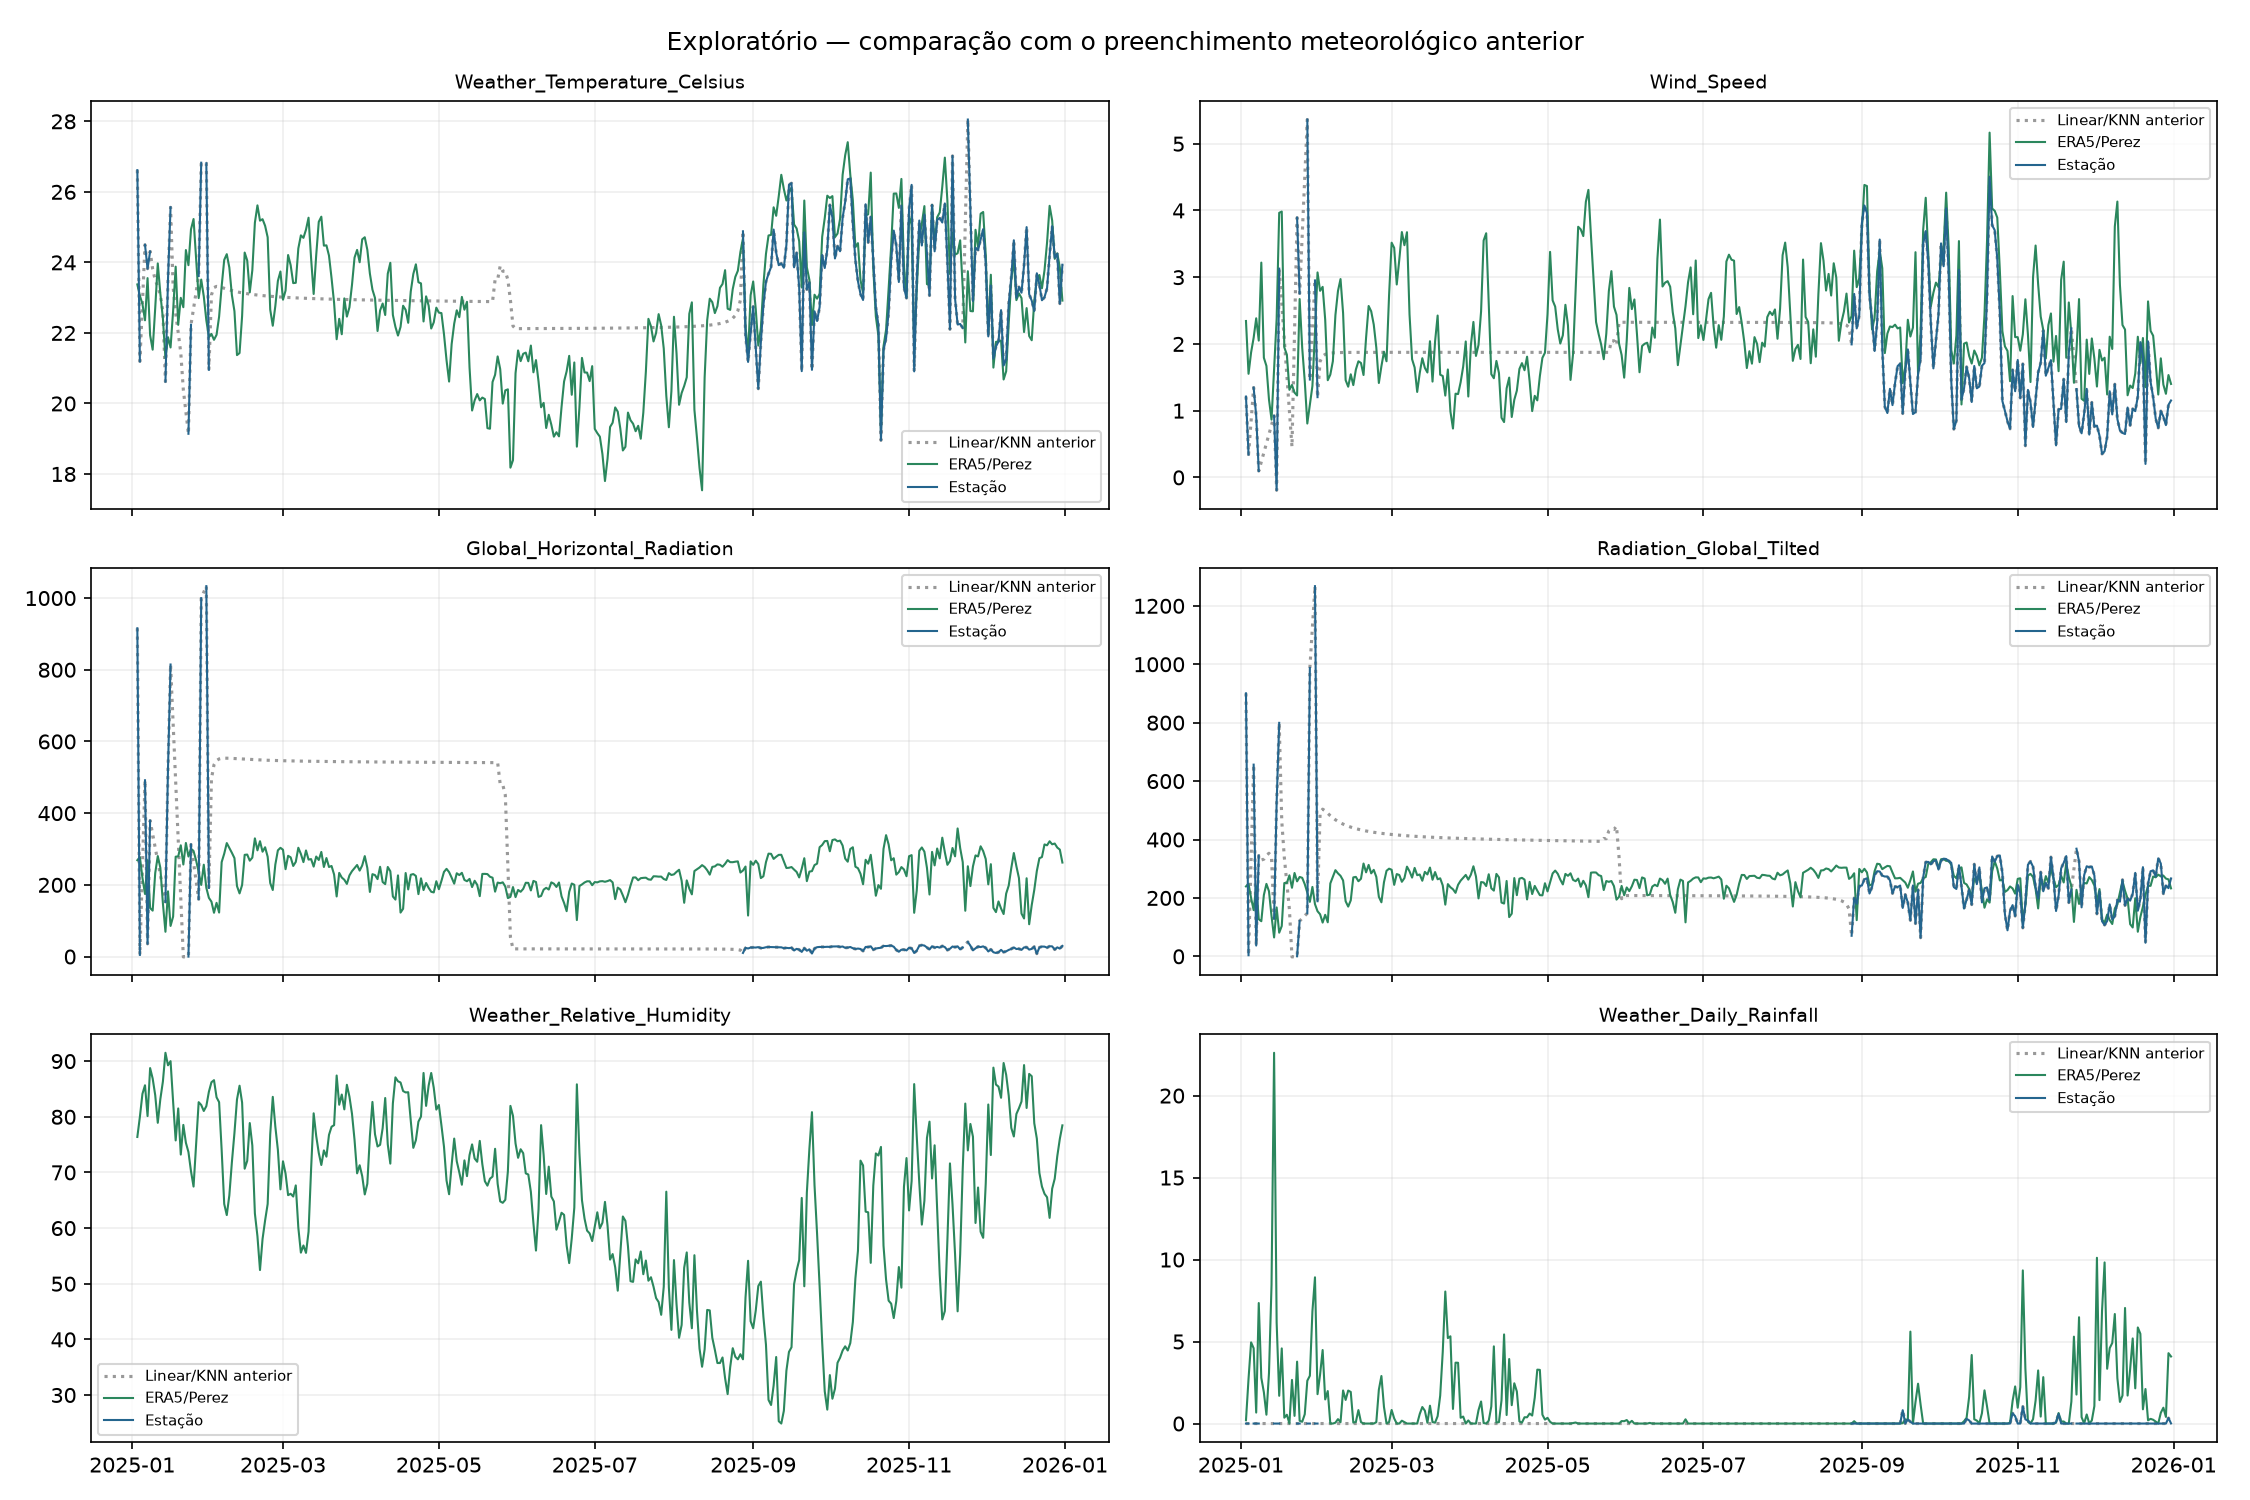

In [3]:
display(Image(filename=str(CAMINHOS.figuras / "diagnostico_meteorologia_publica.png")))